In [2]:
import json
import pandas as pd

data = []

file = "../../examples/data/Semantic40-T.json"
with open(file, "r") as f:
    # While not end of file
    for l in f:      # If end of file, break
        #Convert to JSON
        d = json.loads(l)
        data.append(d) 
        
df = pd.DataFrame(data)

In [2]:
import mteb
import numpy as np

leaderboard = pd.read_csv("MTEB_leaderboard.csv", index_col=0)

model_metas = mteb.get_model_metas()
full_model_names = [m.name for m in model_metas]


leaderboard["Model_Short"] = leaderboard["Model"].str.extract(r"\[([^\]]+)\]")

model_names = []
for name in leaderboard["Model_Short"]:
    n = ""
    for full_name in full_model_names:
        if str(name) in full_name:
            n = full_name
            model_names.append(full_name)
            break
    if n == "":
        model_names.append(name)

leaderboard["Model"] = model_names
leaderboard.head()


/slurm/homes/sussekl/.conda/envs/textClustEnv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Rank (Borda),Model,Zero-shot,Active Parameters (B),Total Parameters (B),Embedding Dimensions,Max Tokens,Mean (Task),Mean (TaskType),Bitext Mining,Classification,Clustering,Instruction Reranking,Multilabel Classification,Pair Classification,Reranking,Retrieval,STS,Model_Short
0,1,microsoft/harrier-oss-v1-27b,78%,25.599,27.009,5376.0,131072.0,74.27,64.20,86.02,79.95,58.93,5.39,36.44,85.44,67.35,78.27,79.99,harrier-oss-v1-27b
1,2,tencent/KaLM-Embedding-Gemma3-12B-2511,73%,10.759,11.766,3840.0,32768.0,72.32,62.51,83.76,77.88,55.77,5.49,33.03,84.73,67.27,75.66,79.02,KaLM-Embedding-Gemma3-12B-2511
2,3,nvidia/llama-embed-nemotron-8b,99%,6.980,7.505,4096.0,32768.0,69.46,61.09,81.72,73.21,54.35,10.82,29.86,83.97,67.78,68.69,79.41,llama-embed-nemotron-8b
3,4,Qwen/Qwen3-Embedding-8B,99%,6.946,7.567,4096.0,32768.0,70.58,61.69,80.89,74.00,57.65,10.06,28.66,86.40,65.63,70.88,81.08,Qwen3-Embedding-8B
4,5,google/gemini-embedding-001,99%,NaN,NaN,3072.0,2048.0,68.37,59.59,79.28,71.82,54.59,5.18,29.16,83.63,65.58,67.71,79.40,gemini-embedding-001


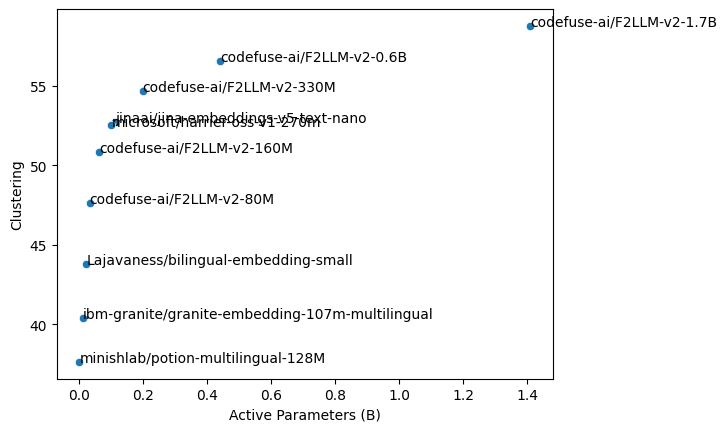

In [3]:
import seaborn as sns
import numpy as np

leaderboard = leaderboard.sort_values(by="Clustering", ascending=False)

lb_df = leaderboard[leaderboard["Active Parameters (B)"]<1.5].reset_index(drop = True)
lb_df = lb_df[~np.isnan(lb_df["Clustering"])]

is_efficient = np.ones(lb_df.shape[0], dtype=bool)

for i, c in lb_df.iterrows():
    if is_efficient[i]:
        is_efficient[i] = not np.any(
            (c["Clustering"]<=lb_df["Clustering"]) & 
            (c["Active Parameters (B)"]>=lb_df["Active Parameters (B)"]) & 
            (c["Model"] != lb_df["Model"]))

lb_df = lb_df[is_efficient]

ax = sns.scatterplot(lb_df, x = "Active Parameters (B)", y = "Clustering")

for _, m in lb_df.iterrows():
    ax.text(x=m["Active Parameters (B)"], y = m["Clustering"], s = m["Model"])

In [4]:
lb_df

,Rank (Borda),Model,Zero-shot,Active Parameters (B),Total Parameters (B),Embedding Dimensions,Max Tokens,Mean (Task),Mean (TaskType),Bitext Mining,Classification,Clustering,Instruction Reranking,Multilabel Classification,Pair Classification,Reranking,Retrieval,STS,Model_Short
0,14,codefuse-ai/F2LLM-v2-1.7B,88%,1.410,1.721,2048.0,40960.0,65.21,56.78,73.18,67.68,58.77,0.56,26.04,79.87,67.17,61.97,75.77,F2LLM-v2-1.7B
1,23,codefuse-ai/F2LLM-v2-0.6B,88%,0.441,0.596,1024.0,40960.0,62.74,55.02,70.31,64.06,56.58,1.39,25.23,78.95,65.14,59.30,74.22,F2LLM-v2-0.6B
2,37,codefuse-ai/F2LLM-v2-330M,88%,0.198,0.334,896.0,40960.0,60.84,53.27,69.80,61.69,54.69,-1.65,24.56,77.79,63.35,56.50,72.73,F2LLM-v2-330M
5,18,jinaai/jina-embeddings-v5-text-nano,⚠️ NA,0.113,0.212,768.0,8192.0,65.52,57.66,67.70,69.18,52.73,0.05,41.31,81.94,64.63,63.26,78.17,jina-embeddings-v5-text-nano
6,16,microsoft/harrier-oss-v1-270m,78%,0.100,0.268,640.0,32768.0,66.55,56.90,81.54,70.84,52.51,-0.47,23.97,80.12,61.90,66.38,75.35,harrier-oss-v1-270m
11,55,codefuse-ai/F2LLM-v2-160M,88%,0.062,0.159,640.0,40960.0,57.98,50.61,65.59,58.86,50.83,-3.39,23.05,76.02,60.34,54.08,70.10,F2LLM-v2-160M
16,65,codefuse-ai/F2LLM-v2-80M,88%,0.032,0.080,320.0,40960.0,55.23,48.62,61.86,55.54,47.66,-1.62,21.50,74.98,58.95,50.13,68.55,F2LLM-v2-80M
25,57,Lajavaness/bilingual-embedding-small,98%,0.022,0.118,384.0,512.0,57.01,49.69,69.48,58.06,43.78,-3.36,19.17,77.07,59.31,49.55,74.14,bilingual-embedding-small
51,79,ibm-granite/granite-embedding-107m-multilingual,96%,0.011,0.107,384.0,512.0,51.81,45.47,54.08,52.57,40.38,-2.96,17.33,75.29,58.48,48.08,65.98,granite-embedding-107m-multilingual
77,106,minishlab/potion-multilingual-128M,97%,0.000,0.128,256.0,NaN,47.23,40.27,40.72,52.36,37.63,-2.08,15.95,71.39,47.39,37.86,61.23,potion-multilingual-128M


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import v_measure_score, homogeneity_score, completeness_score
import time

def k_means(embeddings, n_clusters = 40):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    start_time = time.time()
    kmeans.fit(embeddings)
    labels = kmeans.labels_
    end_time = time.time()
    
    elapsed_time = end_time - start_time
    nmi = normalized_mutual_info_score(df["topic"].tolist(), labels)
    v_measure = v_measure_score(df["topic"].tolist(), labels)
    homogeneity = homogeneity_score(df["topic"].tolist(), labels)
    completeness = completeness_score(df["topic"].tolist(), labels)

    result = {
        "elapsed_time_k_means" : elapsed_time,
        "nmi" : nmi,
        "v_measure" : v_measure,
        "homogeneity" : homogeneity,
        "completeness" : completeness
    }

    return result

In [6]:
import time
from sentence_transformers import SentenceTransformer

models = lb_df["Model"].values

results = []

for model_name in models:
    try:
        print("Testing: "+ model_name)
        transformer = SentenceTransformer(model_name, device="cuda")
        start_time = time.time()
        embeddings = transformer.encode(df["tweets"].tolist(), show_progress_bar=True)
        end_time = time.time()
        
        elapsed_time = end_time - start_time
        result = k_means(embeddings, n_clusters = 40)
        result["model_name"] = model_name
        result["elapsed_time_embeddings"] = elapsed_time
        result["elapsed_time_sum"] = result["elapsed_time_embeddings"] + result["elapsed_time_k_means"]
    
        results.append(result)
    except Exception as ex:
        print("Failed: "+ model_name)
        print(ex)
    


Testing: codefuse-ai/F2LLM-v2-1.7B


Batches: 100%|██████████| 1161/1161 [00:27<00:00, 42.41it/s]


Testing: codefuse-ai/F2LLM-v2-0.6B


Batches: 100%|██████████| 1161/1161 [00:25<00:00, 45.56it/s]


Testing: codefuse-ai/F2LLM-v2-330M


Batches: 100%|██████████| 1161/1161 [00:16<00:00, 71.02it/s]


... (6 outputs left out)

Testing: Lajavaness/bilingual-embedding-small
Failed: Lajavaness/bilingual-embedding-small
The repository Lajavaness/bilingual-embedding-small contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/Lajavaness/bilingual-embedding-small .
 You can inspect the repository content at https://hf.co/Lajavaness/bilingual-embedding-small.
Please pass the argument `trust_remote_code=True` to allow custom code to be run.
Testing: ibm-granite/granite-embedding-107m-multilingual


Batches: 100%|██████████| 1161/1161 [00:07<00:00, 161.63it/s]


Testing: minishlab/potion-multilingual-128M


Batches: 100%|██████████| 1161/1161 [00:01<00:00, 1028.45it/s]


In [7]:
df = pd.DataFrame(results)
df.head()

,elapsed_time_k_means,nmi,v_measure,homogeneity,completeness,model_name,elapsed_time_embeddings,elapsed_time_sum
0,4.091919,0.821277,0.821277,0.822875,0.819684,codefuse-ai/F2LLM-v2-1.7B,27.690750,31.782670
1,2.151016,0.837296,0.837296,0.841539,0.833096,codefuse-ai/F2LLM-v2-0.6B,25.690655,27.841671
2,2.035548,0.799964,0.799964,0.801357,0.798577,codefuse-ai/F2LLM-v2-330M,16.559538,18.595086
3,1.690825,0.870843,0.870843,0.870527,0.871158,microsoft/harrier-oss-v1-270m,26.232931,27.923756
4,1.656143,0.770682,0.770682,0.772688,0.768687,codefuse-ai/F2LLM-v2-160M,10.706562,12.362705


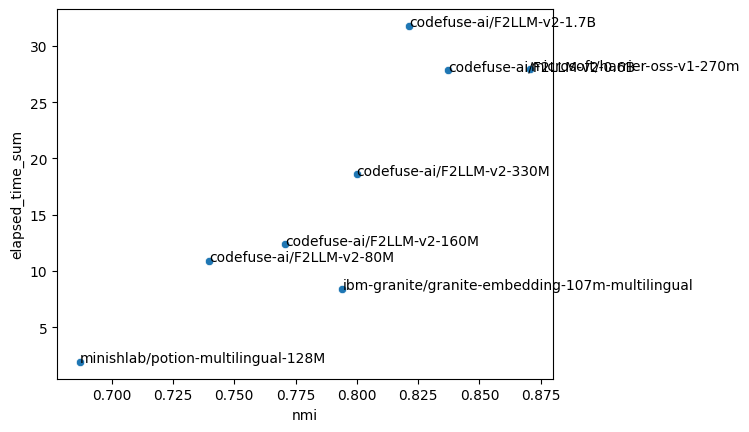

In [8]:
import seaborn as sns
ax = sns.scatterplot(df, x = "nmi", y = "elapsed_time_sum")

for _, row in df.iterrows():
    ax.text(x=row["nmi"], y=row["elapsed_time_sum"], s=row["model_name"])

In [18]:
# Try k-means clustering
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=40, random_state=42)
kmeans.fit(embeddings)
labels = kmeans.labels_

# Check NMI score & v-measure score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import v_measure_score, homogeneity_score, completeness_score
nmi = normalized_mutual_info_score(df["topic"].tolist(), labels)
print(f"NMI score: {nmi}")
v_measure = v_measure_score(df["topic"].tolist(), labels)
print(f"V-measure score: {v_measure}")
homogeneity = homogeneity_score(df["topic"].tolist(), labels)
print(f"Homogeneity score: {homogeneity}")
completeness = completeness_score(df["topic"].tolist(), labels)
print(f"Completeness score: {completeness}")

NMI score: 0.8032776899430569
V-measure score: 0.8032776899430569
Homogeneity score: 0.8050354423154579
Completeness score: 0.801527596766155


In [11]:
import plotly.graph_objects as go
import plotly.express as px

# Crosstab: counts of true → predicted
flows = pd.crosstab(pd.Series(df["topic"].tolist(), name="true"), pd.Series(labels, name="pred"))

# Labels and node indices
true_nodes = [f"T{c}" for c in flows.index]
pred_nodes = [f"P{c}" for c in flows.columns]
labels = true_nodes + pred_nodes
# hover_labels = ["<br>".join(f"{term}:{count}" for term, count in word_counts_true[c_id].items()) for c_id in flows.index] + \
#                 ["<br>".join(f"{term}:{count}" for term, count in word_counts_pred[int(c_id[1:])].items()) for c_id in pred_nodes]
label_idx = {label:i for i,label in enumerate(labels)}

# Sources, targets, values
sources, targets, values = [], [], []
for t in flows.index:
    for p in flows.columns:
        count = int(flows.loc[t,p]) #type: ignore
        if count > 0:
            sources.append(label_idx[f"T{t}"])
            targets.append(label_idx[f"P{p}"])
            values.append(count)

# Sankey plot
fig = go.Figure(
    go.Sankey(
        node=dict(
            label=labels), 
        link=dict(
            source=sources, 
            target=targets, 
            value=values))) 


fig.update_layout(height=4000)
fig.show()

In [42]:
# Try DBSCAN
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.187931, min_samples=1, metric="cosine") #Params via grid search
dbscan.fit(embeddings)
labels = dbscan.labels_

# Check NMI score & v-measure score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import v_measure_score, homogeneity_score, completeness_score
nmi = normalized_mutual_info_score(df["topic"].tolist(), labels)
print(f"NMI score: {nmi}")
v_measure = v_measure_score(df["topic"].tolist(), labels)
print(f"V-measure score: {v_measure}")
homogeneity = homogeneity_score(df["topic"].tolist(), labels)
print(f"Homogeneity score: {homogeneity}")
completeness = completeness_score(df["topic"].tolist(), labels)
print(f"Completeness score: {completeness}")

NMI score: 0.5796159792142807
V-measure score: 0.5796159792142807
Homogeneity score: 0.8680715581416274
Completeness score: 0.4350508778163832


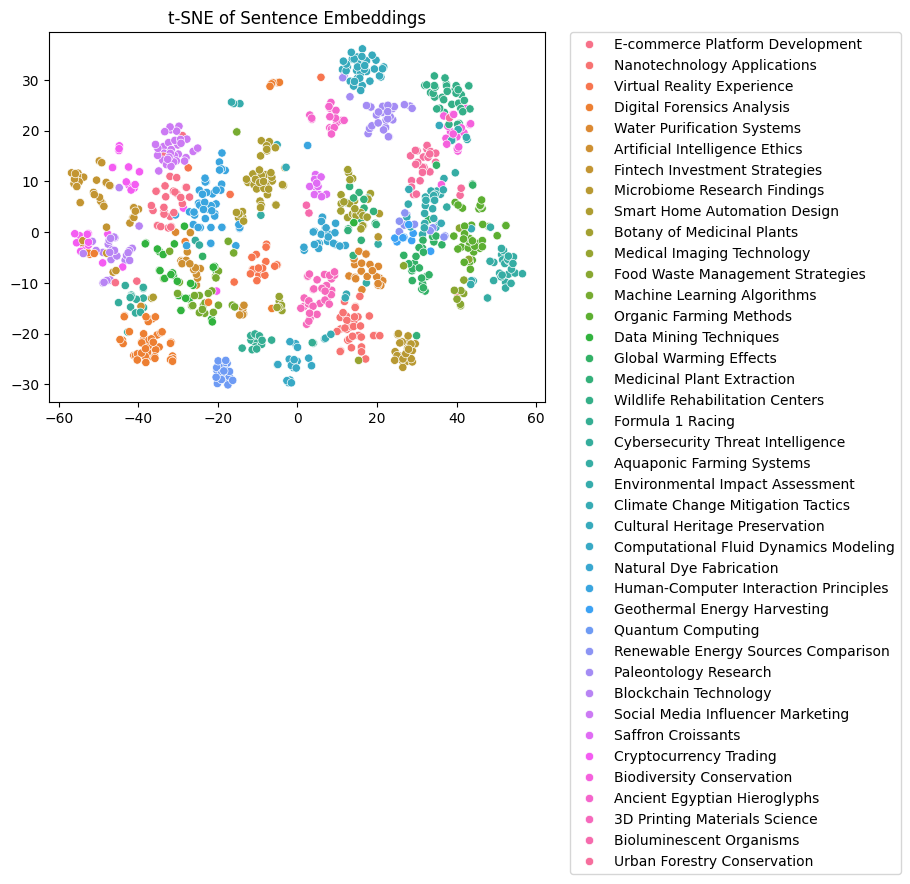

In [25]:
# Do t-sne
from sklearn.manifold import TSNE
import numpy as np
tsne = TSNE(n_components=2, random_state=42)

np.random.seed(42)

sampled_embedding_ids = np.random.choice(len(embeddings), size=1000, replace=False) 
sampled_embeddings = embeddings[sampled_embedding_ids]
sampled_embedding_labels = [df["topic"].tolist()[i] for i in sampled_embedding_ids]

tsne_embeddings = tsne.fit_transform(sampled_embeddings)
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(x=tsne_embeddings[:,0], y=tsne_embeddings[:,1], hue=sampled_embedding_labels)
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.title("t-SNE of Sentence Embeddings")
plt.show()


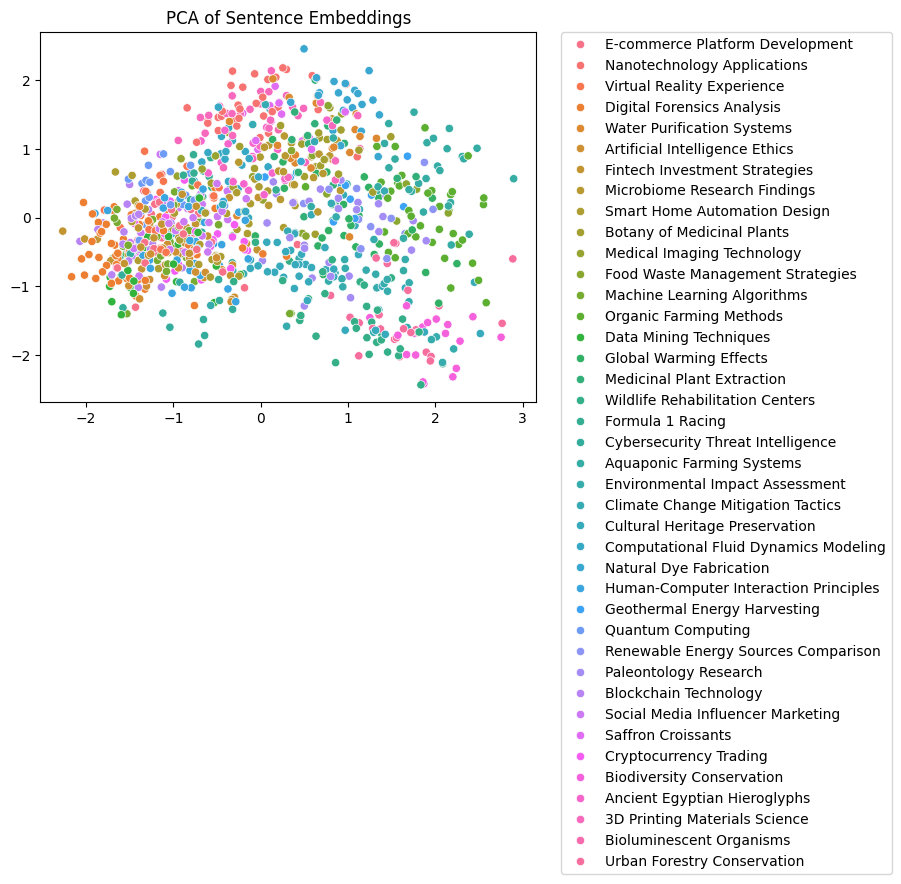

In [26]:
# Do PCA
import numpy as np
from sklearn.decomposition import PCA

np.random.seed(42)

pca = PCA(n_components=2, random_state=42)

sampled_embedding_ids = np.random.choice(len(embeddings), size=1000, replace=False) 
sampled_embeddings = embeddings[sampled_embedding_ids]
sampled_embedding_labels = [df["topic"].tolist()[i] for i in sampled_embedding_ids]

pca_embeddings = pca.fit_transform(sampled_embeddings)

import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(x=pca_embeddings[:,0], y=pca_embeddings[:,1], hue=sampled_embedding_labels)
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.title("PCA of Sentence Embeddings")
plt.show()

In [19]:
import os
from huggingface_hub import InferenceClient

client = InferenceClient(
    provider="scaleway",
    api_key=os.environ["HF_TOKEN"],
)

In [20]:
def get_detailed_instruct(task_description: str, query: str) -> str:
    return f'Instruct: {task_description}\nQuery:{query}'

# Each query must come with a one-sentence instruction that describes the task
task = 'Given several topics, decide which one describes the topic of the query best.'

query1 = get_detailed_instruct(
    task_description=task,
    query="Today I make my favorite dish, which is a delicious pasta with tomato sauce and fresh basil.",
)

query2 = get_detailed_instruct(
    task_description=task,  
    query="Putting the cake in the oven is the best part of it.",
)

topics = [
    "Cooking",
    "Baking",
    "Women",
    "Men"
]



In [21]:
result1 = client.feature_extraction(
    query1,
    model="Qwen/Qwen3-Embedding-8B")

result2 = client.feature_extraction(
    query2,
    model="Qwen/Qwen3-Embedding-8B")

topics_result1 = client.feature_extraction(
    topics[0],
    model="Qwen/Qwen3-Embedding-8B")

topics_result2 = client.feature_extraction(
    topics[1],
    model="Qwen/Qwen3-Embedding-8B")

topics_result3 = client.feature_extraction(
    topics[2],
    model="Qwen/Qwen3-Embedding-8B")

In [22]:
topics_result4 = client.feature_extraction(
    topics[3],
    model="Qwen/Qwen3-Embedding-8B")

In [23]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

similarity1 = cosine_similarity(result1, topics_result1)
similarity2 = cosine_similarity(result1, topics_result2)
similarity3 = cosine_similarity(result1, topics_result3)
similarity4 = cosine_similarity(result1, topics_result4)

print(f"Similarity between query1 and topic 'Cooking': {similarity1[0][0]:.4f}")
print(f"Similarity between query1 and topic 'Baking': {similarity2[0][0]:.4f}")
print(f"Similarity between query1 and topic 'Women': {similarity3[0][0]:.4f}")
print(f"Similarity between query1 and topic 'Men': {similarity4[0][0]:.4f}")

similarity1 = cosine_similarity(result2, topics_result1)
similarity2 = cosine_similarity(result2, topics_result2)
similarity3 = cosine_similarity(result2, topics_result3)
similarity4 = cosine_similarity(result2, topics_result4)

print(f"Similarity between query2 and topic 'Cooking': {similarity1[0][0]:.4f}")
print(f"Similarity between query2 and topic 'Baking': {similarity2[0][0]:.4f}")
print(f"Similarity between query2 and topic 'Women': {similarity3[0][0]:.4f}")
print(f"Similarity between query2 and topic 'Men': {similarity4[0][0]:.4f}")


Similarity between query1 and topic 'Cooking': 0.5766
Similarity between query1 and topic 'Baking': 0.4585
Similarity between query1 and topic 'Women': 0.2406
Similarity between query1 and topic 'Men': 0.2456
Similarity between query2 and topic 'Cooking': 0.5211
Similarity between query2 and topic 'Baking': 0.6166
Similarity between query2 and topic 'Women': 0.2437
Similarity between query2 and topic 'Men': 0.2486


In [1]:
# Requires transformers>=4.51.0
# Requires sentence-transformers>=2.7.0

from sentence_transformers import SentenceTransformer

# Load the model
model = SentenceTransformer("Qwen/Qwen3-Embedding-8B")

# We recommend enabling flash_attention_2 for better acceleration and memory saving,
# together with setting `padding_side` to "left":
# model = SentenceTransformer(
#     "Qwen/Qwen3-Embedding-8B",
#     model_kwargs={"attn_implementation": "flash_attention_2", "device_map": "auto"},
#     tokenizer_kwargs={"padding_side": "left"},
# )


/Users/lms/Documents/textClust/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 4 files:   0%|          | 0/4 [00:06<?, ?it/s]
Cancellation requested; stopping current tasks.


KeyboardInterrupt: 

In [ ]:

# The queries and documents to embed
queries = [
    "What is the capital of China?",
    "Explain gravity",
]
documents = [
    "The capital of China is Beijing.",
    "Gravity is a force that attracts two bodies towards each other. It gives weight to physical objects and is responsible for the movement of planets around the sun.",
]

# Encode the queries and documents. Note that queries benefit from using a prompt
# Here we use the prompt called "query" stored under `model.prompts`, but you can
# also pass your own prompt via the `prompt` argument
query_embeddings = model.encode(queries, prompt_name="query")
document_embeddings = model.encode(documents)

# Compute the (cosine) similarity between the query and document embeddings
similarity = model.similarity(query_embeddings, document_embeddings)
print(similarity)
# tensor([[0.7493, 0.0751],
#         [0.0880, 0.6318]])
